In [1]:
pip install plotly kagglehub IProgress ipywidgets pandas seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#**Brazilian E-commerce project: RFM approach**
In this project, I will analyse the **Brazilian E-Commerce Public Dataset** using the **RFM approach**, a common method for customer segmentation based on purchasing behaviour:

- **R — Recency:** how recently a customer made a purchase.
- **F — Frequency:** how often a customer makes purchases.
- **M — Monetary:** how much money a customer has spent.

Using these three metrics, I will segment customers into groups such as loyal customers, high-value customers, and customers at risk of becoming inactive. This analysis aims to provide a better understanding of customer purchasing behaviour within the Brazilian e-commerce dataset.

---



##**1. Data Preparation & Data Quality**

Before performing the RFM analysis, the dataset was explored to understand its structure, identify potential data quality issues, and determine which records should be included.

The analysis uses the Brazilian E-Commerce Public Dataset by Olist, which contains information about orders, customers, payments, and other aspects of e-commerce transactions.

This preparation stage focuses on examining the available data, checking missing values and duplicates, reviewing order statuses, and identifying the appropriate customer identifier for the analysis.

###1.1 Data Overview



In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Path to dataset files: /Users/anakace/.cache/kagglehub/datasets/olistbr/brazilian-ecommerce/versions/2


In [3]:
import os
import pandas as pd

os.listdir(path)

['olist_sellers_dataset.csv',
 'product_category_name_translation.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv']

In [4]:
# Load and preview all datasets
datasets = {}

for file in sorted(os.listdir(path)):
    if file.endswith('.csv'):
        filename = file.split('.')[0].replace("_", " ")
        datasets[filename] = pd.read_csv(os.path.join(path, file))

        print(f"\nDataset: {filename}")
        print(f"Rows: {datasets[filename].shape[0]:,} | Columns: {datasets[filename].shape[1]}")
        display(datasets[filename].head())


Dataset: olist customers dataset
Rows: 99,441 | Columns: 5


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Dataset: olist geolocation dataset
Rows: 1,000,163 | Columns: 5


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



Dataset: olist order items dataset
Rows: 112,650 | Columns: 7


...

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



Dataset: olist sellers dataset
Rows: 3,095 | Columns: 4


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



Dataset: product category name translation
Rows: 71 | Columns: 2


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


###1.2 Data Quality Checks

Before calculating the RFM metrics, the datasets were examined for missing values, duplicate records, and data types. These checks help identify potential inconsistencies that could affect the accuracy of the analysis.

In [5]:
# Loop through all datasets to check for missing values
for name, df in datasets.items():
    print(f"\nDataset: {name}")
    print(f"Rows: {df.shape[0]:,}")
    display(df.isnull().sum())


Dataset: olist customers dataset
Rows: 99,441


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


Dataset: olist geolocation dataset
Rows: 1,000,163


geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64


Dataset: olist order items dataset
Rows: 112,650


...

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


Dataset: olist sellers dataset
Rows: 3,095


seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64


Dataset: product category name translation
Rows: 71


product_category_name            0
product_category_name_english    0
dtype: int64

In [6]:
# Check for duplicate rows across all datasets

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicated rows")

olist customers dataset: 0 duplicated rows
olist geolocation dataset: 261831 duplicated rows
olist order items dataset: 0 duplicated rows
olist order payments dataset: 0 duplicated rows
olist order reviews dataset: 0 duplicated rows
olist orders dataset: 0 duplicated rows
olist products dataset: 0 duplicated rows
olist sellers dataset: 0 duplicated rows
product category name translation: 0 duplicated rows


The data quality checks identified missing values in some columns and a substantial number of duplicate records in the Geolocation dataset. However, the main datasets used for the RFM analysis (Orders, Customers, and Payments) contained no fully duplicated rows, and the key columns used in the analysis had no missing values. As the Geolocation dataset was not required for this analysis, its duplicate records did not affect the RFM calculations.

In [7]:
# Check data types across all datasets

for name, df in datasets.items():
    print(f"\nDataset: {name}")
    display(df.dtypes)


Dataset: olist customers dataset


customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object


Dataset: olist geolocation dataset


geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object


Dataset: olist order items dataset


...

product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object


Dataset: olist sellers dataset


seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str
dtype: object


Dataset: product category name translation


product_category_name            str
product_category_name_english    str
dtype: object

In [8]:
#Rename some of the datasets
orders = datasets['olist orders dataset']
customers = datasets['olist customers dataset']
orders.head(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [9]:
# Check the distribution of order statuses
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [10]:
# Calculate the percentage of orders by status
orders['order_status'].value_counts(normalize=True).mul(100).round(2)

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

In [11]:
# Keep only delivered orders for RFM analysis
orders = orders[orders['order_status'] == 'delivered'].copy()

The order status analysis showed that 97.02% of orders were delivered, while the remaining 2.98% were classified as shipped, cancelled, unavailable, or in other stages of processing.

For the RFM analysis, only delivered orders were retained to ensure that Recency, Frequency, and Monetary were calculated using completed transactions. This resulted in 96,478 orders being considered for the analysis.

###1.3 Data Preparation Decisions

Based on the initial data exploration and quality checks, the following decisions were made to prepare the dataset for RFM analysis.

**Order Status:** Only orders with the status `delivered` were included in the analysis. These represent 97.02% of all orders (96,478 out of 99,441). This decision ensures that the RFM metrics are based on completed transactions rather than cancelled or incomplete orders.

**Customer Identification:** The `customer_unique_id` was selected to identify individual customers. In the Olist dataset, `customer_id` identifies a customer record associated with an order, while `customer_unique_id` allows multiple orders belonging to the same customer to be grouped together. This distinction is essential for calculating purchase frequency and total spending per customer.

**Monetary Value:** Customer spending was calculated using `payment_value` from the order payments dataset. Payments associated with the same customer were summed to calculate their total monetary value, including orders with multiple payment records.

**Data Integration:** The orders, customers, and payments datasets were linked using their corresponding identifiers (`order_id` and `customer_id`). These relationships allow Recency, Frequency, and Monetary metrics to be calculated at the individual customer level.

These decisions establish a consistent basis for calculating the RFM metrics and performing customer segmentation.



## **2. Recency**

Recency measures the number of days since a customer's most recent purchase. Since this analysis uses historical transaction data, recency was calculated relative to the latest purchase date available in the filtered dataset, rather than the current date.

Customers with more recent purchases receive higher Recency scores, while those who have not purchased for longer receive lower scores.

In [12]:
# Select only the columns needed for the analysis
orders_subset = orders[['order_id', 'customer_id', 'order_purchase_timestamp']]
orders_subset

,order_id,customer_id,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39
...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,2017-03-09 09:54:05
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,2018-02-06 12:58:58
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,2017-08-27 14:46:43
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,2018-01-08 21:28:27


In [13]:
orders_subset.columns

Index(['order_id', 'customer_id', 'order_purchase_timestamp'], dtype='str')

In [14]:
# join orders_subset with customers
orders_subset = orders_subset.merge(
    customers[['customer_id','customer_unique_id']],
    on ='customer_id'
)
orders_subset

,order_id,customer_id,order_purchase_timestamp,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6
...,...,...,...,...
96473,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,2017-03-09 09:54:05,6359f309b166b0196dbf7ad2ac62bb5a
96474,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,2018-02-06 12:58:58,da62f9e57a76d978d02ab5362c509660
96475,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,2017-08-27 14:46:43,737520a9aad80b3fbbdad19b66b37b30
96476,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,2018-01-08 21:28:27,5097a5312c8b157bb7be58ae360ef43c


In [15]:
#Reorder the columns
orders_subset = orders_subset[['customer_id', 'customer_unique_id', 'order_id', 'order_purchase_timestamp']]
orders_subset.head()

,customer_id,customer_unique_id,order_id,order_purchase_timestamp
0,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33
1,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37
2,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49
3,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06
4,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39


In [16]:
#Check dtype of purchase date column
orders_subset['order_purchase_timestamp'].dtype

<StringDtype(storage='python', na_value=nan)>

In [17]:
#Convert columns to datetime
orders_subset['order_purchase_timestamp'] = pd.to_datetime(
    orders_subset['order_purchase_timestamp']
)

In [18]:
#Find out the latest day/time
latest_date = max(orders_subset['order_purchase_timestamp'])
latest_date

Timestamp('2018-08-29 15:00:37')

In [19]:
# Calculate the number of days since each customer's last purchase
orders_subset['recency'] = (
  latest_date - orders_subset['order_purchase_timestamp']
).dt.days
orders_subset.head()

,customer_id,customer_unique_id,order_id,order_purchase_timestamp,recency
0,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,331
1,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,35
2,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,21
3,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,283
4,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,196


In [20]:
# Sort list of unique customers by the recency of their last purchase
recency_list = orders_subset.groupby('customer_unique_id', as_index = False).agg(
    purchase_day = ('order_purchase_timestamp', 'max'),
    recency = ('recency', 'min')
).sort_values(by = 'recency', ascending = True)
recency_list.head(30)

,customer_unique_id,purchase_day,recency
61041,a712a430955027da5bc257a10073a390,2018-08-28 21:56:30,0
57667,9dfcc502727549f99c9f73dbd28b35e9,2018-08-28 22:30:32,0
83805,e58697e3a253c253e1582f8c4f4c54ff,2018-08-28 19:31:41,0
73840,ca36d819c1759cdb6257fef0bb5d362d,2018-08-28 18:49:20,0
59751,a3bf67d0b92528d2fe5c379dd905bf66,2018-08-28 19:44:25,0
13158,23e6a9d387ba03e2099233222d7635cf,2018-08-28 15:11:49,0
31368,55cfdb1ec3c5bf60d9ccc0d5f276f8a9,2018-08-28 15:58:28,0
66821,b701bebbdf478f5500348f03aff62121,2018-08-29 14:52:00,0
64218,afbcfd0b9c5233e7ccc73428526fbb52,2018-08-29 08:46:11,0
91722,fb7e29c65321441231990afc201c1b14,2018-08-28 19:32:05,0


In [21]:
# Assign Recency scores (R_code) from 5 to 1.
# The most recent 20% of customers receive a score of 5,
# while the least recent 20% receive a score of 1.

recency_list['R_code'] = pd.qcut(
    recency_list['recency'],
    q = 5,
    labels = [5, 4, 3, 2, 1]
)
recency_list

,customer_unique_id,purchase_day,recency,R_code
61041,a712a430955027da5bc257a10073a390,2018-08-28 21:56:30,0,5
57667,9dfcc502727549f99c9f73dbd28b35e9,2018-08-28 22:30:32,0,5
83805,e58697e3a253c253e1582f8c4f4c54ff,2018-08-28 19:31:41,0,5
73840,ca36d819c1759cdb6257fef0bb5d362d,2018-08-28 18:49:20,0,5
59751,a3bf67d0b92528d2fe5c379dd905bf66,2018-08-28 19:44:25,0,5
...,...,...,...,...
17806,30a38716bb2d04f12bb813aa2f926270,2016-10-04 13:30:13,694,1
18041,31463a6b3a01f53c3ef1a04a849decf4,2016-10-04 13:16:57,694,1
42237,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,694,1
42996,75b181fe0ef694c753c72540c0fdd389,2016-10-04 13:40:43,694,1


##**3. Frequency**

Frequency measures the number of purchases made by each customer during the period covered by the dataset. Higher frequency values indicate customers who have made repeated purchases, while lower values indicate occasional or one-time buyers.

Frequency scores (F_code) are assigned based on the distribution of purchase counts across customers.

In [22]:
# Count the number of purchases made by each customer
frequency_list = orders_subset.groupby('customer_unique_id', as_index=False).agg(
    frequency=('order_id', 'nunique')
).sort_values(by='frequency', ascending=False)

frequency_list

,customer_unique_id,frequency
51431,8d50f5eadf50201ccdcedfb9e2ac8455,15
22779,3e43e6105506432c953e165fb2acf44c,9
36706,6469f99c1f9dfae7733b25662e7f1782,7
73921,ca77025e7201e3b30c44b472ff346268,7
10060,1b6c7548a2a1f9037c1fd3ddfed95f33,7
...,...,...
31564,565811ed44e539a14bc391cf57373ed1,1
31563,5657f9f721c16800a66c21081d46b18d,1
31562,5657dfebff5868c4dc7e8355fea865c4,1
31561,5657596addb4d7b07b32cd330614bdf8,1


In [23]:
frequency_list['frequency'].value_counts().sort_index()

frequency
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [24]:
# Use pd.cut instead of pd.qcut because most customers made only one purchase.

frequency_list['F_code'] = pd.cut(
    frequency_list['frequency'],
    bins=[0, 1, 2, 4, 6, float('inf')],
    labels=[1, 2, 3, 4, 5])
frequency_list

,customer_unique_id,frequency,F_code
51431,8d50f5eadf50201ccdcedfb9e2ac8455,15,5
22779,3e43e6105506432c953e165fb2acf44c,9,5
36706,6469f99c1f9dfae7733b25662e7f1782,7,5
73921,ca77025e7201e3b30c44b472ff346268,7,5
10060,1b6c7548a2a1f9037c1fd3ddfed95f33,7,5
...,...,...,...
31564,565811ed44e539a14bc391cf57373ed1,1,1
31563,5657f9f721c16800a66c21081d46b18d,1,1
31562,5657dfebff5868c4dc7e8355fea865c4,1,1
31561,5657596addb4d7b07b32cd330614bdf8,1,1


In [25]:
#checking
frequency_list[frequency_list['F_code'] == 5][['frequency','F_code']]

,frequency,F_code
51431,15,5
22779,9,5
36706,7,5
73921,7,5
10060,7,5


##**4. Monetary**

Monetary measures the total amount spent by each customer during the period covered by the dataset. Higher monetary values indicate customers who have contributed more to the total transaction value.

For this analysis, Monetary is calculated using `payment_value` from the order payments dataset, considering only delivered orders. Multiple payment records associated with the same order are included in the total amount spent.

Customers are then assigned Monetary scores (M_code) from 1 to 5 based on their spending distribution.

To calculate the Monetary value for each customer, three datasets need to be combined:

- **Order Payments:** Contains `order_id` and `payment_value`, representing the payments associated with each order.
- **Orders:** Contains `order_id` and `customer_id`, allowing payments to be linked to customer records.
- **Customers:** Contains `customer_id` and `customer_unique_id`, allowing purchases to be associated with individual customers.

First, the Order Payments dataset is merged with the Orders dataset using `order_id`. The resulting DataFrame is then merged with the Customers dataset using `customer_id`.

Finally, `payment_value` is summed for each `customer_unique_id` to calculate the total amount spent by each customer.

In [26]:
#merging dataset payments and orders
monetary =  datasets['olist order payments dataset'][['order_id', 'payment_value']].merge(
   orders[['order_id', 'customer_id']],
   on = 'order_id'
)
monetary

,order_id,payment_value,customer_id
0,b81ef226f3fe1789b1e8b2acac839d17,99.33,0a8556ac6be836b46b3e89920d59291c
1,a9810da82917af2d9aefd1278f1dcfa0,24.39,f2c7fc58a9de810828715166c672f10a
2,25e8ea4e93396b6fa0d3dd708e76c1bd,65.71,25b14b69de0b6e184ae6fe2755e478f9
3,ba78997921bbcdc1373bb41e913ab953,107.78,7a5d8efaaa1081f800628c30d2b0728f
4,42fdf880ba16b47b59251dd489d4441a,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3
...,...,...,...
100751,c45067032fd84f4cf408730ff5205568,198.94,0fea3afc6a1510c9db75d349d28af974
100752,0406037ad97740d563a178ecc7a2075c,363.31,5d576cb2dfa3bc05612c392a1ee9c654
100753,7b905861d7c825891d6347454ea7863f,96.80,2079230c765a88530822a34a4cec2aa0
100754,b8b61059626efa996a60be9bb9320e10,369.54,5d719b0d300663188169c6560e243f27


In [27]:
#Reorder the columns
monetary = monetary[['order_id', 'customer_id', 'payment_value']]
monetary

,order_id,customer_id,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,0a8556ac6be836b46b3e89920d59291c,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,f2c7fc58a9de810828715166c672f10a,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,25b14b69de0b6e184ae6fe2755e478f9,65.71
3,ba78997921bbcdc1373bb41e913ab953,7a5d8efaaa1081f800628c30d2b0728f,107.78
4,42fdf880ba16b47b59251dd489d4441a,15fd6fb8f8312dbb4674e4518d6fa3b3,128.45
...,...,...,...
100751,c45067032fd84f4cf408730ff5205568,0fea3afc6a1510c9db75d349d28af974,198.94
100752,0406037ad97740d563a178ecc7a2075c,5d576cb2dfa3bc05612c392a1ee9c654,363.31
100753,7b905861d7c825891d6347454ea7863f,2079230c765a88530822a34a4cec2aa0,96.80
100754,b8b61059626efa996a60be9bb9320e10,5d719b0d300663188169c6560e243f27,369.54


In [28]:
#Merge monetary and customer
monetary = monetary.merge(
    customers[['customer_id', 'customer_unique_id']],
    on = 'customer_id'
)
monetary

,order_id,customer_id,payment_value,customer_unique_id
0,b81ef226f3fe1789b1e8b2acac839d17,0a8556ac6be836b46b3e89920d59291c,99.33,708ab75d2a007f0564aedd11139c7708
1,a9810da82917af2d9aefd1278f1dcfa0,f2c7fc58a9de810828715166c672f10a,24.39,a8b9d3a27068454b1c98cc67d4e31e6f
2,25e8ea4e93396b6fa0d3dd708e76c1bd,25b14b69de0b6e184ae6fe2755e478f9,65.71,6f70c0b2f7552832ba46eb57b1c5651e
3,ba78997921bbcdc1373bb41e913ab953,7a5d8efaaa1081f800628c30d2b0728f,107.78,87695ed086ebd36f20404c82d20fca87
4,42fdf880ba16b47b59251dd489d4441a,15fd6fb8f8312dbb4674e4518d6fa3b3,128.45,4291db0da71914754618cd789aebcd56
...,...,...,...,...
100751,c45067032fd84f4cf408730ff5205568,0fea3afc6a1510c9db75d349d28af974,198.94,13f283df2f4760f22b57830865761d07
100752,0406037ad97740d563a178ecc7a2075c,5d576cb2dfa3bc05612c392a1ee9c654,363.31,b6027ac07fb76ebca8c97b1887865aee
100753,7b905861d7c825891d6347454ea7863f,2079230c765a88530822a34a4cec2aa0,96.80,53b30ca78efb2b7efcd3f9e461587eb2
100754,b8b61059626efa996a60be9bb9320e10,5d719b0d300663188169c6560e243f27,369.54,b84dc68f02f122a88d7e7bbd37b06204


In [29]:
#Calculation of purchases sum by unique customer
monetary_list = monetary.groupby('customer_unique_id', as_index = False).agg(
    purchases_amount = ('payment_value', 'sum'),
).sort_values(by = 'purchases_amount', ascending = False)
monetary_list

,customer_unique_id,purchases_amount
3724,0a0a92112bd4c708ca5fde585afaa872,13664.08
79635,da122df9eeddfedc1dc1f5349a1a690c,7571.63
43168,763c8b1c9c68a0229c42c9fc6f662b93,7274.88
80462,dc4802a71eae9be1dd28f5d788ceb526,6929.31
25436,459bef486812aa25204be022145caa62,6922.21
...,...,...
14799,2878e5b88167faab17d4fb83a986d38b,11.63
40696,6f5b9d1cdccc4d28f0483a612edecacf,11.63
65458,b33336f46234b24a613ad9064d13106d,10.89
69026,bd06ce0e06ad77a7f681f1a4960a3cc6,10.07


<Axes: xlabel='purchases_amount', ylabel='Count'>

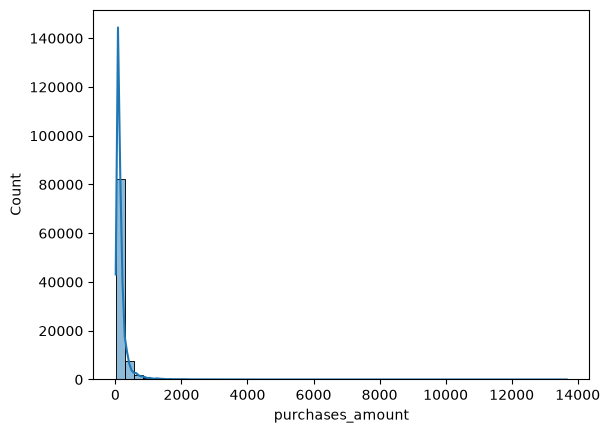

In [30]:
# Explore the distribution of customer spending
import seaborn as sns
import matplotlib as plt
sns.histplot(
    data=monetary_list,
    x='purchases_amount',
    bins=50,
    kde=True
)



In [31]:
# Create M_code by dividing customers into five quantile-based spending groups
monetary_list['M_code'] = pd.qcut(
    monetary_list['purchases_amount'],
    q = 5,
    labels = [1, 2, 3, 4, 5])
monetary_list

,customer_unique_id,purchases_amount,M_code
3724,0a0a92112bd4c708ca5fde585afaa872,13664.08,5
79635,da122df9eeddfedc1dc1f5349a1a690c,7571.63,5
43168,763c8b1c9c68a0229c42c9fc6f662b93,7274.88,5
80462,dc4802a71eae9be1dd28f5d788ceb526,6929.31,5
25436,459bef486812aa25204be022145caa62,6922.21,5
...,...,...,...
14799,2878e5b88167faab17d4fb83a986d38b,11.63,1
40696,6f5b9d1cdccc4d28f0483a612edecacf,11.63,1
65458,b33336f46234b24a613ad9064d13106d,10.89,1
69026,bd06ce0e06ad77a7f681f1a4960a3cc6,10.07,1


In [32]:
#Checking
monetary_list[monetary_list['M_code'] == 3][['customer_unique_id', 'M_code', 'purchases_amount']]

,customer_unique_id,M_code,purchases_amount
38777,6a1789624e4dd9c4e708f5f886a65160,3,132.69
78113,d5b925479d2fd6b3a38bde7196ecbd02,3,132.69
63688,ae6bbe4153dc872187e955bb9838a1bb,3,132.69
92970,fef64e867815034175d876d16048ced8,3,132.69
4394,0bdb1b5e412a2098545a552a2c091686,3,132.69
...,...,...,...
61768,a936a09f5e56a028c5ba4d6f6b744495,3,87.38
69873,bf432226a944503e91c6ec2159c6663e,3,87.38
52836,911d8d8b9caf08632be0ed8889151d8d,3,87.38
81523,df25efeec134052aa0bca8b60e9e5592,3,87.37



##**5. RFM Analysis**

After calculating Recency, Frequency, and Monetary separately, the three metrics were combined into a single DataFrame using `customer_unique_id`.

Each customer was assigned an RFM score based on their purchasing behaviour. The individual scores (`R_code`, `F_code`, and `M_code`) were then combined to create an `RFM_code`, which provides a summary of each customer's purchasing profile.

These scores form the basis for the customer segmentation presented in the next section.



In [33]:
#Joining R_Code, F_Code, M_Code
RFM = recency_list[['customer_unique_id', 'purchase_day','recency', 'R_code']].merge(
    frequency_list[['customer_unique_id', 'frequency', 'F_code']],
    on = 'customer_unique_id'
)
RFM

,customer_unique_id,purchase_day,recency,R_code,frequency,F_code
0,a712a430955027da5bc257a10073a390,2018-08-28 21:56:30,0,5,1,1
1,9dfcc502727549f99c9f73dbd28b35e9,2018-08-28 22:30:32,0,5,1,1
2,e58697e3a253c253e1582f8c4f4c54ff,2018-08-28 19:31:41,0,5,1,1
3,ca36d819c1759cdb6257fef0bb5d362d,2018-08-28 18:49:20,0,5,1,1
4,a3bf67d0b92528d2fe5c379dd905bf66,2018-08-28 19:44:25,0,5,1,1
...,...,...,...,...,...,...
93353,30a38716bb2d04f12bb813aa2f926270,2016-10-04 13:30:13,694,1,1,1
93354,31463a6b3a01f53c3ef1a04a849decf4,2016-10-04 13:16:57,694,1,1,1
93355,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,694,1,1,1
93356,75b181fe0ef694c753c72540c0fdd389,2016-10-04 13:40:43,694,1,1,1


In [34]:
# Merge Monetary data with Recency and Frequency

RFM = RFM.merge(
    monetary_list[['customer_unique_id', 'purchases_amount', 'M_code']],
    on = 'customer_unique_id'
)
RFM

,customer_unique_id,purchase_day,recency,R_code,frequency,F_code,purchases_amount,M_code
0,a712a430955027da5bc257a10073a390,2018-08-28 21:56:30,0,5,1,1,161.97,4
1,9dfcc502727549f99c9f73dbd28b35e9,2018-08-28 22:30:32,0,5,1,1,98.04,3
2,e58697e3a253c253e1582f8c4f4c54ff,2018-08-28 19:31:41,0,5,1,1,185.82,4
3,ca36d819c1759cdb6257fef0bb5d362d,2018-08-28 18:49:20,0,5,1,1,14.89,1
4,a3bf67d0b92528d2fe5c379dd905bf66,2018-08-28 19:44:25,0,5,1,1,128.99,3
...,...,...,...,...,...,...,...,...
93352,4be873e3bf0455763882101d7eccc78c,2016-10-04 10:41:17,694,1,1,1,214.98,5
93353,30a38716bb2d04f12bb813aa2f926270,2016-10-04 13:30:13,694,1,1,1,119.43,3
93354,31463a6b3a01f53c3ef1a04a849decf4,2016-10-04 13:16:57,694,1,1,1,177.28,4
93355,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,694,1,1,1,154.57,4


In [35]:
RFM[['R_code', 'F_code', 'M_code']].dtypes

R_code    category
F_code    category
M_code    category
dtype: object

In [36]:
#Changing the R_code to string to create the final RFM_code
RFM['RFM_code'] = (
    RFM['R_code'].astype(str)
    + RFM['F_code'].astype(str)
    + RFM['M_code'].astype(str)
)
RFM

,customer_unique_id,purchase_day,recency,R_code,frequency,F_code,purchases_amount,M_code,RFM_code
0,a712a430955027da5bc257a10073a390,2018-08-28 21:56:30,0,5,1,1,161.97,4,514
1,9dfcc502727549f99c9f73dbd28b35e9,2018-08-28 22:30:32,0,5,1,1,98.04,3,513
2,e58697e3a253c253e1582f8c4f4c54ff,2018-08-28 19:31:41,0,5,1,1,185.82,4,514
3,ca36d819c1759cdb6257fef0bb5d362d,2018-08-28 18:49:20,0,5,1,1,14.89,1,511
4,a3bf67d0b92528d2fe5c379dd905bf66,2018-08-28 19:44:25,0,5,1,1,128.99,3,513
...,...,...,...,...,...,...,...,...,...
93352,4be873e3bf0455763882101d7eccc78c,2016-10-04 10:41:17,694,1,1,1,214.98,5,115
93353,30a38716bb2d04f12bb813aa2f926270,2016-10-04 13:30:13,694,1,1,1,119.43,3,113
93354,31463a6b3a01f53c3ef1a04a849decf4,2016-10-04 13:16:57,694,1,1,1,177.28,4,114
93355,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,694,1,1,1,154.57,4,114


In [37]:
#Checking how many clients in each category
RFM['RFM_code'].value_counts().sort_index()

RFM_code
111    3880
112    3905
113    3628
114    3292
115    3498
       ... 
533       4
534       5
535      44
545       4
555       3
Name: count, Length: 73, dtype: int64

In [38]:
#Changing the codes, except RFM, to integer
RFM['R_code'] = RFM['R_code'].astype(int)
RFM['F_code'] = RFM['F_code'].astype(int)
RFM['M_code'] = RFM['M_code'].astype(int)



In [39]:
#from google.colab import files
#files.download('RFM.csv')

##**5.1 Customer Segmentation**

Customers were classified into seven segments based on their Recency, Frequency, and Monetary (RFM) scores. This segmentation helps identify different purchasing behaviours and potential opportunities for customer retention, engagement, and reactivation.

**Champions** are the most valuable customers, with high scores across all three RFM dimensions. They have purchased recently, buy frequently, and have a high total spending value.

**Loyal Customers** are customers who purchase relatively frequently and have made purchases recently. Although their monetary value may vary, their repeated purchasing behaviour indicates an established relationship with the business.

**Recent Buyers with Potential** are customers who have purchased relatively recently but have not yet established a consistent purchasing pattern. With approximately 96% having purchased only once, this segment represents an opportunity to encourage repeat purchases and develop longer-term customer relationships.

**Valuable Customers at Risk** are customers who have previously demonstrated relatively high purchasing frequency and monetary value but have not purchased as recently as other active segments. They may benefit from targeted reactivation strategies.

**Occasional Customers** are customers with moderate recency scores and relatively low purchasing frequency. They have not developed a regular purchasing pattern and may benefit from initiatives designed to increase engagement.

**Lost Customers** are customers who have not purchased for a relatively long period and generally show low purchasing frequency or monetary value. Depending on their previous spending behaviour, businesses may consider reactivation campaigns or prioritise resources towards more active segments.

**Recent Low-Value Customers** are customers who have purchased recently but have relatively low monetary value and limited purchasing frequency. They may benefit from personalised recommendations or incentives designed to encourage additional purchases.

The segmentation was implemented using a rule-based classification system, with conditions evaluated sequentially to assign each customer to a single segment. The resulting groups provide a basis for understanding customer behaviour and identifying potential business actions.


In [40]:
#creating the customers segments
def classify_client(row):
    if row['R_code'] >= 4 and row['F_code'] >= 4 and row['M_code'] >= 4:
        return 'Champions'

    elif row['F_code'] >= 3 and row['R_code'] >= 3:
        return 'Loyal Customers'

    elif row['R_code'] >= 4 and (row['F_code'] >= 2 or row['M_code'] >= 2):
        return 'Recent Buyers with Potential'

    elif row['R_code'] <= 3 and row['F_code'] >= 2 and row['M_code'] >= 3:
        return 'Valuable customers at risk'

    elif row['R_code'] == 3 and row['F_code'] <= 2:
        return 'Occasional Customers'

    elif row['R_code'] <= 2 and (row['F_code'] <= 2 or row['M_code'] <= 2):
        return 'Lost Customers'

    elif row['R_code'] >=4 and row['M_code'] <= 3:
        return 'Recent Low-Value Customers'

    else:
        return 'Other'

In [41]:
#applying the function above to the RFM dataframe
RFM['segment'] = RFM.apply(classify_client, axis=1)
RFM


,customer_unique_id,purchase_day,recency,R_code,frequency,F_code,purchases_amount,M_code,RFM_code,segment
0,a712a430955027da5bc257a10073a390,2018-08-28 21:56:30,0,5,1,1,161.97,4,514,Recent Buyers with Potential
1,9dfcc502727549f99c9f73dbd28b35e9,2018-08-28 22:30:32,0,5,1,1,98.04,3,513,Recent Buyers with Potential
2,e58697e3a253c253e1582f8c4f4c54ff,2018-08-28 19:31:41,0,5,1,1,185.82,4,514,Recent Buyers with Potential
3,ca36d819c1759cdb6257fef0bb5d362d,2018-08-28 18:49:20,0,5,1,1,14.89,1,511,Recent Low-Value Customers
4,a3bf67d0b92528d2fe5c379dd905bf66,2018-08-28 19:44:25,0,5,1,1,128.99,3,513,Recent Buyers with Potential
...,...,...,...,...,...,...,...,...,...,...
93352,4be873e3bf0455763882101d7eccc78c,2016-10-04 10:41:17,694,1,1,1,214.98,5,115,Lost Customers
93353,30a38716bb2d04f12bb813aa2f926270,2016-10-04 13:30:13,694,1,1,1,119.43,3,113,Lost Customers
93354,31463a6b3a01f53c3ef1a04a849decf4,2016-10-04 13:16:57,694,1,1,1,177.28,4,114,Lost Customers
93355,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,694,1,1,1,154.57,4,114,Lost Customers


In [42]:
#Check number of customers per each segment
RFM['segment'].value_counts()

segment
Lost Customers                  36308
Recent Buyers with Potential    29993
Occasional Customers            18131
Recent Low-Value Customers       7318
Valuable customers at risk       1448
Loyal Customers                   145
Champions                          14
Name: count, dtype: int64

In [43]:
RFM.groupby('segment').agg(
    total_customers=('customer_unique_id', 'count'),
    one_time_buyers=('frequency', lambda x: (x == 1).sum()),
    average_frequency=('frequency', 'mean')
).round(2)

,total_customers,one_time_buyers,average_frequency
segment,,,
Champions,14,0,6.21
Lost Customers,36308,36227,1.00
Loyal Customers,145,0,3.25
Occasional Customers,18131,18105,1.00
Recent Buyers with Potential,29993,28906,1.04
Recent Low-Value Customers,7318,7318,1.00
Valuable customers at risk,1448,0,2.05


In [44]:
#Check number of customers per each R_code
RFM.groupby('R_code').agg(
      total = ('customer_unique_id', 'count'),
      when = ('purchase_day', 'mean'),
      how_many_times = ('frequency', 'mean'),
      how_much = ('purchases_amount', 'mean')

  ).round(2)


/var/folders/6v/8dr_hqsj5lj5tzhkw7htrd8m0000gn/T/ipykernel_21903/2035478208.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,total,when,how_many_times,how_much
R_code,,,,
1,18638,2017-05-13 17:06:11.592713,1.03,162.86
2,18577,2017-10-17 18:06:17.913118,1.03,167.87
3,18709,2018-01-21 17:32:23.298466,1.04,156.39
4,18705,2018-04-16 10:45:51.931943,1.04,170.22
5,18728,2018-07-15 13:10:47.447138,1.04,168.65


In [45]:
#Check number of customers per each F_code

RFM.groupby('F_code').agg(
      total = ('customer_unique_id', 'count'),
      when = ('purchase_day', 'mean'),
      how_many_times = ('frequency', 'mean'),
      how_much = ('purchases_amount', 'mean')
  )

,total,when,how_many_times,how_much
F_code,,,,
1,90556,2018-01-03 14:48:43.210035,1.000000,160.763556
2,2573,2018-01-20 05:16:36.792071,2.000000,291.025410
3,209,2018-02-03 14:24:53.755980,3.133971,481.015024
4,14,2018-03-25 02:06:12.571428,5.357143,723.157143
5,5,2018-05-13 17:31:04.000000,9.000000,978.498000


In [46]:
#Check number of customers per each M_code

RFM.groupby('M_code').agg(
      total = ('customer_unique_id', 'count'),
      when = ('purchase_day', 'mean'),
      how_many_times = ('frequency', 'mean'),
      how_much = ('purchases_amount', 'mean')
  )

,total,when,how_many_times,how_much
M_code,,,,
1,18673,2018-01-01 22:13:21.335993,1.001499,39.696241
2,18683,2017-12-28 12:53:21.566771,1.008457,70.532761
3,18658,2018-01-05 13:42:23.254153,1.021331,108.520062
4,18675,2018-01-11 09:25:52.862168,1.039625,165.174995
5,18668,2018-01-04 09:25:24.926558,1.096207,442.149129


In [47]:
#Summary for each segment

summary = RFM.groupby('segment', as_index = False).agg(
      total = ('customer_unique_id', 'count'),
      when = ('purchase_day', 'mean'),
      how_many_times = ('frequency', 'mean'),
      how_much = ('purchases_amount', 'mean'),
      total_payment = ('purchases_amount', 'sum'),
      recency_avg = ('recency', 'mean')


  ).round(2)

/var/folders/6v/8dr_hqsj5lj5tzhkw7htrd8m0000gn/T/ipykernel_21903/2249320740.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


In [48]:
summary['percentage'] = (
    summary['total_payment'] / summary['total_payment'].sum()
) * 100

In [49]:
summary['when'] = summary['when'].dt.strftime('%d/%m/%Y')
summary

,segment,total,when,how_many_times,how_much,total_payment,recency_avg,percentage
0,Champions,14,27/05/2018,6.21,807.12,11299.71,94.07,0.073268
1,Lost Customers,36308,30/07/2017,1.00,161.69,5870732.50,394.38,38.066118
2,Loyal Customers,145,30/04/2018,3.25,516.68,74918.31,120.82,0.485774
3,Occasional Customers,18131,21/01/2018,1.00,151.23,2741887.87,219.44,17.778536
4,Recent Buyers with Potential,29993,31/05/2018,1.04,199.56,5985365.33,89.76,38.809403
5,Recent Low-Value Customers,7318,01/06/2018,1.00,39.58,289627.83,88.82,1.877961
6,Valuable customers at risk,1448,14/10/2017,2.05,309.83,448630.22,318.27,2.908940


In [50]:
summary = summary.sort_values(
    by='how_much',
    ascending=False
)
summary

,segment,total,when,how_many_times,how_much,total_payment,recency_avg,percentage
0,Champions,14,27/05/2018,6.21,807.12,11299.71,94.07,0.073268
2,Loyal Customers,145,30/04/2018,3.25,516.68,74918.31,120.82,0.485774
6,Valuable customers at risk,1448,14/10/2017,2.05,309.83,448630.22,318.27,2.908940
4,Recent Buyers with Potential,29993,31/05/2018,1.04,199.56,5985365.33,89.76,38.809403
1,Lost Customers,36308,30/07/2017,1.00,161.69,5870732.50,394.38,38.066118
3,Occasional Customers,18131,21/01/2018,1.00,151.23,2741887.87,219.44,17.778536
5,Recent Low-Value Customers,7318,01/06/2018,1.00,39.58,289627.83,88.82,1.877961


##**6. Data Visualizations**

This section presents the results of the RFM analysis through visualisations, highlighting customer segments, purchasing behaviour, and potential business opportunities.

In [51]:
import plotly.io as pio

pio.renderers.default = "notebook_connected"

In [52]:
## Customer Distribution by RFM Segment
import plotly.express as px

fig = px.bar(
    summary,
    x ='total',
    y = 'segment',
    orientation= 'h',
    text = 'total',
    title = 'Figure 1 - Customer Distribution by RFM Segment',
    color = 'segment',
    color_discrete_sequence= px.colors.qualitative.Plotly,
    template = 'plotly_white'
    )
fig.update_yaxes(categoryorder='total ascending')
fig.update_traces(
    texttemplate='%{x:,}',
    textposition='outside',
    cliponaxis = False
)
fig.update_xaxes(range=[0, summary['total'].max() * 1.15])
fig.update_layout(showlegend=False)
fig.update_layout(
    xaxis_title='Number of Customers',
    yaxis_title='Customer Segment',
    title=dict(
        text = 'Figure 1 - Customer Distribution by RFM Segment',
        x=0.5,
        y=0.93,
        xanchor='center',
        yanchor='top',
        font=dict(size=20)
     )
    # title=dict(
    #     x = 0.5,
    #     xref='paper',
    #     xanchor='center',
    #     font=dict(size=20))
)
fig.show()

This chart shows the number of customers in each RFM segment, highlighting the relative size of each group within the customer base.

In [53]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

In [54]:
fig = make_subplots(
    rows=2,
    cols=1,
    specs=[
        [{"type": "domain"}],
        [{"type": "table"}]
    ],
    row_heights=[0.7, 0.3],
    vertical_spacing=0.05
)

treemap = px.treemap(
    summary,
    path=['segment'],
    values = 'total_payment',
    title = 'Figure 2 — Total Payment Value by Customer Segment',
    color = 'segment',
    color_discrete_sequence= px.colors.qualitative.Plotly,
    template = 'plotly_white'

)


fig.add_trace(
    treemap.data[0],
    row=1,
    col=1
)
fig.add_trace(
    go.Table(
        header=dict(
    values=['Customer Segment', 'Total Payment (R$)', 'Percentage'],
    fill_color= '#94A3B8',
    font=dict(color='white', size=13),
    align='left',
    height=32
),

cells=dict(
    values=[
        summary['segment'],
        summary['total_payment'].map(lambda x: f'R$ {x:,.2f}'),
        summary['percentage'].map(lambda x: f'{x:.1f}%')
    ],
    fill_color=[
        ['#FFFFFF', '#F5F6F8'] * 4
    ],
    font=dict(color='#344054', size=12),
    align='left',
    height=28
)),
    row=2,
    col=1
)
fig.update_layout(
    uniformtext=dict(
        minsize=12,
        mode='hide'
    )
)
fig.update_traces(
    texttemplate='%{label}<br>R$ %{value:,.0f}<br>%{percentRoot:.1%}',
    textposition='middle center',
    selector=dict(type='treemap')
)


fig.update_traces(
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Total Payment: R$ %{value:,.2f}<br>'
        'Share: %{percentRoot:.1%}'
        '<extra></extra>'
    ),
    selector=dict(type='treemap')
)
fig.update_layout(
    height=900,
    showlegend=False
)
fig.update_layout(
    title=dict(
        text = 'Figure 2 — Total Payment Value by Customer Segment',
        x=0.5,
        y=0.93,
        xanchor='center',
        yanchor='top',
        font=dict(size=20)
     ),
    margin=dict(t=80, b=30, l=40, r=40),
    height=900,
    showlegend=False,
    template='plotly_white'
)

fig.show()

This treemap shows how the total payment value from delivered orders is distributed across customer segments. The size of each area represents the total amount paid by customers in that segment. The accompanying table provides a more detailed breakdown of these values. It's particularly important to those with smaller shares that may be difficult to distinguish in the treemap.

In [55]:
fig = px.bar(
    summary,
    x= 'how_much',
    y= 'segment',
    text = 'how_much',
    color = 'segment',
    color_discrete_sequence= px.colors.qualitative.Plotly,
    title = 'Figure 3 - Average Customer Spending by RFM Segment',
    template='plotly_white'
    )
fig.update_traces(
    textposition = 'outside',
    cliponaxis = False,
    texttemplate='R$ %{x:,.0f}'
)
fig.update_layout(
    xaxis_title = 'Average Spending per Customer (R$)',
    yaxis_title = 'Customer Segments',
    showlegend = False,
    title=dict(
        text = 'Figure 3 - Average Customer Spending by RFM Segment',
        x=0.5,
        y=0.93,
        xanchor='center',
        yanchor='top',
        font=dict(size=20)
     )

)
fig.update_yaxes(categoryorder='total ascending')

fig.show()

This chart shows the average amount spent per customer in each RFM segment during the period covered by the dataset. It is calculated by dividing the segment's total payment value by its number of customers.

In [58]:
fig = px.bar(
    summary,
    x= 'recency_avg',
    y= 'segment',
    text = 'recency_avg',
    color = 'segment',
    color_discrete_sequence= px.colors.qualitative.Plotly,
    title = 'Figure 4 — Average Recency by RFM Segment',
    template='plotly_white'
    )
fig.update_traces(
    textposition = 'outside',
    texttemplate='%{x:,.0f} days',
    cliponaxis = False
)
fig.update_layout(
    xaxis_title = 'Days Since Last Purchase',
    yaxis_title = 'Customer Segments',
    showlegend = False,
    title=dict(
        text = 'Figure 4 — Average Recency by RFM Segment',
        x=0.5,
        y=0.93,
        xanchor='center',
        yanchor='top',
        font=dict(size=20))

)
fig.update_yaxes(categoryorder='total descending')

fig.show()

Recency is measured in days relative to the latest purchase date in the dataset, rather than the current date. A lower recency value indicates a more recent purchase.

In [57]:
fig = px.bar(
    summary,
    x = 'how_many_times',
    y = 'segment',
    text = 'how_many_times',
    color = 'segment',
    color_discrete_sequence=px.colors.qualitative.Plotly,
    title = 'Figure 5 - Average Number of Purchases per Customer by RFM Segment',
    template = 'plotly_white'

)

fig.update_layout(
    xaxis_title = 'Average Number of Purchases per Customer',
    yaxis_title = 'Customer Segments',
    showlegend = False,
    title = dict(
        x = 0.5,
        xref='paper',
        xanchor='center',
        font=dict(size=20))
    )

fig.update_traces(
    textposition = 'outside'

)
fig.show()

This chart shows the average number of delivered orders per customer in each segment during the period covered by the dataset. Higher values indicate more frequent purchasing behaviour.

##**7. Key Findings & Business Implications**

##7.1 Low Purchase Frequency

One of the most notable findings is that the vast majority of customers made only one purchase during the period covered by the dataset.

This purchasing pattern helps explain why the Champions and Loyal Customers segments are relatively small compared to other customer groups.

Although making a single purchase does not necessarily mean that a customer is dissatisfied or unlikely to return, the results highlight an opportunity for the business to explore strategies that encourage repeat purchases and strengthen customer retention, particularly among customers who have purchased recently.

### 7.1 Opportunities Among Recent Buyers

The Recent Buyers with Potential segment includes 29,993 customers, representing approximately 32% of the customer base and 38.8% of the total payment value.

Despite their relatively recent purchasing activity, approximately 96.4% of these customers have made only one purchase, with an average purchase frequency of 1.04.

These findings suggest that this segment represents an important opportunity for the business. Encouraging these customers to make a second purchase could help develop longer-term customer relationships and increase repeat purchasing activity.

### 7.2 High Historical Spending Among Inactive Customers

The Lost Customers segment includes 36,308 customers, representing approximately 39% of the customer base and 38.1% of the total payment value from delivered orders.

With an average recency of approximately 394 days, these customers have not made a purchase for a relatively long period compared to other segments.

Although these customers are classified as lost based on their RFM scores, they account for a substantial share of historical spending. This suggests that the business could investigate opportunities to re-engage some of these customers, particularly those who previously spent higher amounts.

### 7.3 Small Loyal Customer Base

The Champions and Loyal Customers segments are notably small, comprising only 14 and 145 customers, respectively, out of a total of 93,357 customers.

Despite their small size, these groups show stronger purchasing behaviour than other segments. Champions have the highest average purchase frequency, while both groups demonstrate relatively high average spending per customer.

This finding reinforces the observation that repeat purchasing is uncommon in the dataset. It also highlights the importance of maintaining relationships with existing loyal customers while exploring opportunities to encourage repeat purchases among other segments.

## 8. Limitations

This analysis has some limitations that should be considered when interpreting the results.

First, the dataset contains historical transactions from a limited period. Customers classified as inactive or lost may have made purchases after the period covered by the data.

Second, RFM segmentation is based on predefined scoring thresholds and classification rules. Different criteria could result in different customer segments.

Finally, RFM analysis describes past purchasing behaviour but does not explain customers' motivations or predict their future purchases. Therefore, the business opportunities identified in this project should be considered suggestions for further investigation rather than guaranteed outcomes.